In [1]:
import pandas as pd 

In [2]:
df = pd.read_parquet('processed\\df_staging_2.parquet')

In [3]:
df_x = df.drop(df.columns[403:],axis=1)
df_y = df.drop(df.columns[:403],axis=1)

In [4]:
df_x = df_x.drop(columns=['supported_languages','full_audio_languages'])
labels = list(df_y.columns)


In [5]:

#for future model targets scaling 
genres_cols = [c for c in df_y.columns if c.startswith("genres:")]
tags_cols   = [c for c in df_y.columns if c.startswith("tags:")]
cat_cols    = [c for c in df_y.columns if c.startswith("categories:")]

In [6]:
df_y = df_y[genres_cols +cat_cols] 

In [7]:
df_x.select_dtypes( 'string')


df_x_t = pd.get_dummies(
    df_x,
    columns=['release_month','price_status'],
    prefix=['m_','status_']
)

In [ ]:

#transforming the data into tensors 

import torch   
df_x_t = df_x_t.astype('float32')
X_t = torch.from_numpy(df_x_t.to_numpy())
print(X_t.shape, X_t.dtype)   # torch.Size([139496, 414]) torch.float32
df_y_t = df_y.astype('float32')
Y_t = torch.from_numpy(df_y_t.to_numpy())
print(Y_t.shape, Y_t.dtype)


torch.Size([139496, 414]) torch.float32
torch.Size([139496, 130]) torch.float32


C:\Users\Moha\AppData\Local\Temp\ipykernel_19236\1528426901.py:6: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  Y_t = torch.from_numpy(df_y_t.to_numpy())


In [9]:
import numpy as np 
import torch 
import torch.nn as nn 
import matplotlib
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader
import torchmetrics
from torchmetrics.aggregation import MeanMetric
from copy import deepcopy

In [10]:
device = torch.device('cuda' if torch.cuda.is_available() else "cpu") 
torch.manual_seed(42)
np.random.seed(42)
std = StandardScaler()


In [11]:
X_train, X_test, Y_train, Y_test = train_test_split(X_t, Y_t, test_size=0.2, random_state=42)
X_test, X_val, Y_test, Y_val = train_test_split(X_test,Y_test,test_size=0.5,random_state= 42)


In [12]:
X_train,X_test, X_val = std.fit_transform(X_train), std.transform(X_test), std.transform(X_val)

In [ ]:

#MODEL CLASS

class GenCatMLP(nn.Module):
    def __init__(self,in_dim,out_dim,hidden = 1024,p=0.5):
        super().__init__()
        def block(ins,outs):
            return nn.Sequential(
                nn.Linear(ins,outs),
                nn.ReLU(),
                nn.Dropout(p),
                

            )
        self.net = nn.Sequential(block(in_dim,hidden),block(hidden,hidden//2),block(hidden//2,hidden//4),nn.Linear(hidden//4, out_dim))

    def forward(self,x):
        return self.net(x)
        


In [ ]:
#loss function 
loss_fn = nn.BCEWithLogitsLoss()

In [ ]:

#dtype correction 
X_train = torch.from_numpy(X_train).float()
X_val   = torch.from_numpy(X_val).float()
X_test  = torch.from_numpy(X_test).float()

TypeError: expected np.ndarray (got Tensor)

In [ ]:
def train_model(X_train, Y_train, X_val, Y_val, name, epochs=200):

    # CONFIG
    train_losses = []
    val_losses = []
    mAP = []  # macro-averaged average precision
    best_model_path = f"models/best_{name}.pth"
    tune_model = False
    save_model = False


    # CHECKPOINTS
    model = GenCatMLP(X_train.shape[1], Y_train.shape[1]).to(device)
    if tune_model is True:
        try:
            model.load_state_dict(torch.load(best_model_path, map_location=device))
        except FileNotFoundError:
            print('No best model was found starting from zero')


    # OPTIMIZER
    optim = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-2,
    )


    # METRICS
    train_loss_metric = torchmetrics.aggregation.MeanMetric().to(device)
    val_mAP_metric = torchmetrics.classification.MultilabelAveragePrecision(Y_val.shape[1], average='macro').to(device)
    val_loss_metric = torchmetrics.aggregation.MeanMetric().to(device)

    best_metric = -1.0
    best_epoch = -1


    # DATALOADERS
    train_loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=2048, shuffle=True)
    val_loader   = DataLoader(TensorDataset(X_val, Y_val),     batch_size=512,  shuffle=False)


    # TRAINING LOOP
    for epoch in range(epochs):

        model.train()
        train_loss_metric.reset()

        for xb, yb in train_loader:

            xb, yb = xb.to(device), yb.to(device)
            optim.zero_grad()

            loss = loss_fn(model(xb), yb)
            train_loss_metric.update(loss.item(), weight=xb.size(0))

            loss.backward()
            optim.step()

        train_losses.append(train_loss_metric.compute().item())

        model.eval()
        val_mAP_metric.reset()
        val_loss_metric.reset()

        with torch.inference_mode():

            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                val_loss_metric.update(loss_fn(logits, yb).item(), weight=xb.size(0))
                val_mAP_metric.update(logits, yb.int())

            mAP.append(val_mAP_metric.compute().item())
            val_losses.append(val_loss_metric.compute().item())

            if mAP[-1] > best_metric:
                best_metric = mAP[-1]
                best_epoch = epoch
                torch.save(deepcopy(model.state_dict()), best_model_path)

        if epoch % 50 == 0:
            print(f'[{name}] Training loss = {train_losses[-1]} validation loss is {val_losses[-1]}, mAP = {mAP[-1]}')
            if best_epoch >= 0:
                print(f'[{name}] best so far: mAP = {best_metric:.4f} epoch {best_epoch} -> {best_model_path}')

    return model, mAP, best_metric, best_model_path, val_losses

In [ ]:

#finding out what are the indices for making 2 seperate models 
genres_idx = [df_y.columns.get_loc(c) for c in genres_cols]
cat_idx    = [df_y.columns.get_loc(c) for c in cat_cols]
gencat_idx = genres_idx + cat_idx

# genres only
model_genres, mAP_genres, best_genres, path_genres, val_losses_genres = train_model(
    X_train, Y_train[:, genres_idx],
    X_val,   Y_val[:, genres_idx],
    name='genres'
)

# genres + categories
model_gencat, mAP_gencat, best_gencat, path_gencat, val_losses_gencat = train_model(
    X_train, Y_train[:, gencat_idx],
    X_val,   Y_val[:, gencat_idx],
    name='gencat'
)

c:\Users\Moha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torchmetrics\utilities\prints.py:43: UserWarning: No positive samples found in target, recall is undefined. Setting recall to one for all thresholds.
  warnings.warn(*args, **kwargs)


[genres] Training loss = 0.21191653609275818 validation loss is 0.1520465612411499, mAP = 0.16092315316200256
[genres] best so far: mAP = 0.1609 epoch 0 -> models/best_genres.pth
[genres] Training loss = 0.0951424315571785 validation loss is 0.14934042096138, mAP = 0.26680269837379456
[genres] best so far: mAP = 0.2735 epoch 42 -> models/best_genres.pth
[genres] Training loss = 0.07494212687015533 validation loss is 0.16748495399951935, mAP = 0.2623511850833893
[genres] best so far: mAP = 0.2754 epoch 53 -> models/best_genres.pth
[genres] Training loss = 0.06357542425394058 validation loss is 0.1815195530653, mAP = 0.2538660168647766
[genres] best so far: mAP = 0.2754 epoch 53 -> models/best_genres.pth
[gencat] Training loss = 0.1784919947385788 validation loss is 0.10801246017217636, mAP = 0.08276668936014175
[gencat] best so far: mAP = 0.0828 epoch 0 -> models/best_gencat.pth
[gencat] Training loss = 0.07209350913763046 validation loss is 0.09858004748821259, mAP = 0.1720872968435287

In [100]:
#data sanity check
pos_counts = Y_train.sum(0)
print(f'labels <10 pos:  {(pos_counts < 10).sum()}')
print(f'labels <30 pos:  {(pos_counts < 30).sum()}')
print(f'labels <100 pos: {(pos_counts < 100).sum()}')

labels <10 pos:  40
labels <30 pos:  45
labels <100 pos: 51


In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import average_precision_score

os.makedirs("plots", exist_ok=True)


def eval_model(model, mAP_hist, val_loss_hist, ckpt_path,
               X_test, Y_test, names, tag):
    # load best weights 
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.eval()

    # curves
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(mAP_hist)
    ax[0].set_xlabel('epoch'); ax[0].set_ylabel('mAP')
    ax[0].set_title(f'{tag} mAP')
    ax[0].axhline(max(mAP_hist), color='r', ls='--', alpha=0.5,
                  label=f'best {max(mAP_hist):.3f}')
    ax[0].legend()

    ax[1].plot(val_loss_hist, color='orange')
    ax[1].set_xlabel('epoch'); ax[1].set_ylabel('loss')
    ax[1].set_title(f'{tag} val loss')
    plt.tight_layout()
    plt.savefig(f'plots/{tag}_curves.png', dpi=120)
    plt.show()

    # preds on test
    with torch.inference_mode():
        probs = torch.sigmoid(model(X_test.to(device))).cpu().numpy()
    Yte = Y_test.cpu().numpy()

    ap = average_precision_score(Yte, probs, average=None)

    # ap histogram
    plt.figure(figsize=(8, 4))
    plt.hist(ap, bins=20, edgecolor='black')
    plt.axvline(ap.mean(), color='r', ls='--', label=f'mean {ap.mean():.3f}')
    plt.xlabel('AP'); plt.ylabel('count')
    plt.title(f'{tag} per-label AP')
    plt.legend()
    plt.tight_layout()
    plt.savefig(f'plots/{tag}_ap_hist.png', dpi=120)
    plt.show()

    # sorted bars
    order = np.argsort(ap)[::-1]
    plt.figure(figsize=(max(8, len(ap)*0.35), 5))
    plt.bar(range(len(ap)), ap[order])
    plt.xticks(range(len(ap)),
               [names[i].split(':')[-1] for i in order],
               rotation=90, fontsize=7)
    plt.ylabel('AP')
    plt.title(f'{tag} AP per label (sorted)')
    plt.tight_layout()
    plt.savefig(f'plots/{tag}_ap_per_label.png', dpi=120)
    plt.show()

    # preds vs true
    plt.figure(figsize=(8, 4))
    plt.hist(probs.flatten(), bins=50, alpha=0.6, density=True, label='preds')
    plt.hist(Yte.flatten(), bins=50, alpha=0.6, density=True, label='true')
    plt.yscale('log')
    plt.xlabel('value'); plt.ylabel('density')
    plt.title(f'{tag} preds vs true')
    plt.legend()
    plt.tight_layout()
    plt.savefig(f'plots/{tag}_pred_dist.png', dpi=120)
    plt.show()

    print(f'[{tag}] test mAP    : {ap.mean():.4f}')
    print(f'[{tag}] median AP   : {np.median(ap):.4f}')
    print(f'[{tag}] best val    : {max(mAP_hist):.4f} (epoch {mAP_hist.index(max(mAP_hist))})')
    print(f'[{tag}] labels >0.5 : {(ap > 0.5).sum()}/{len(ap)}')
    print()

    return ap

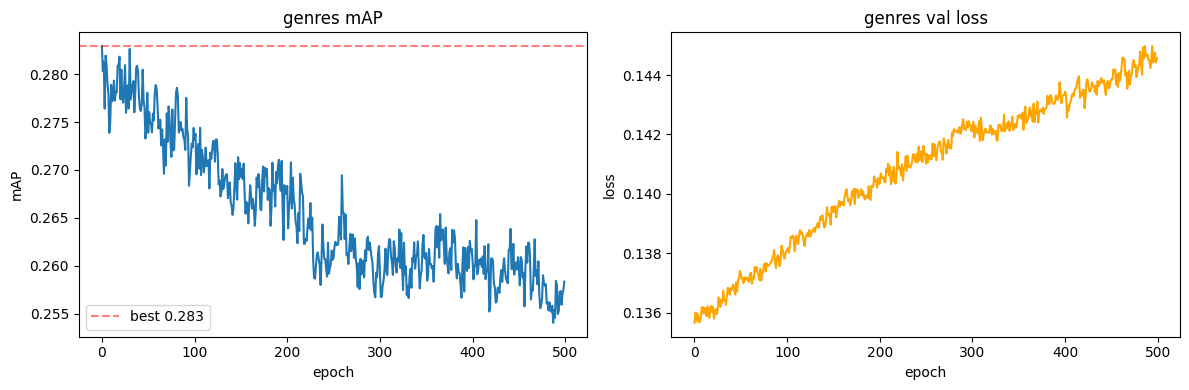

c:\Users\Moha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_ranking.py:1192: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
c:\Users\Moha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_ranking.py:1192: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
c:\Users\Moha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_ranking.py:1192: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
c:\Users\Moha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_ranking.py:1192: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
c:\Users\Moha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_ranking.py:1192: UserWarning: No positive class found in y_true

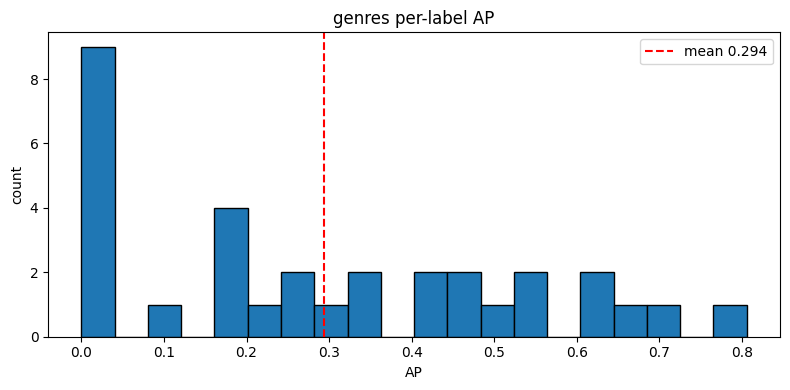

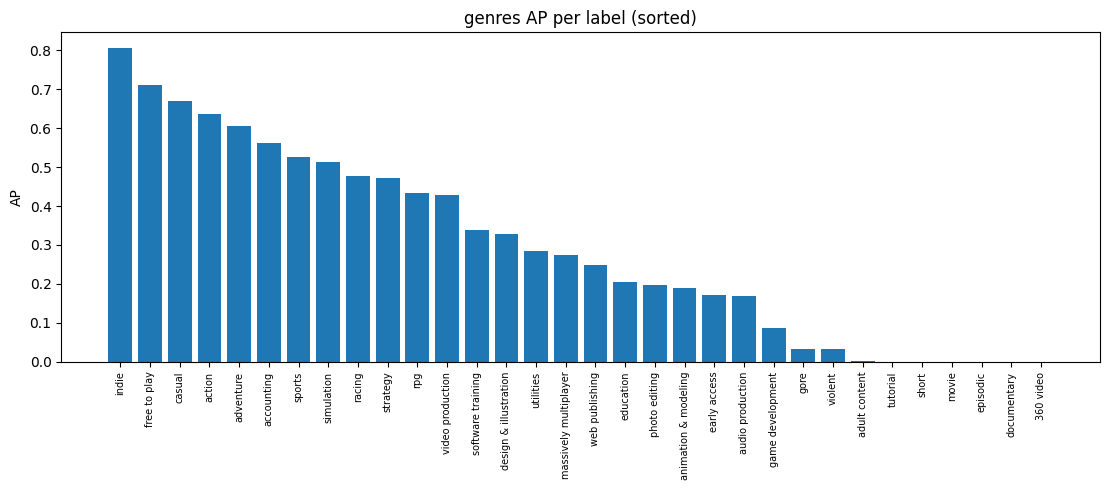

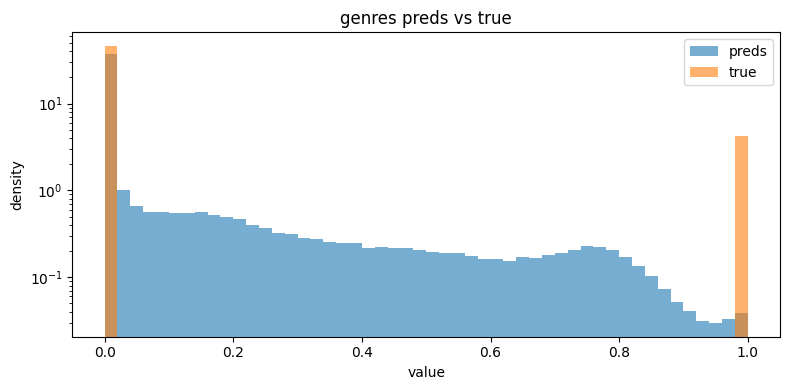

[genres] test mAP    : 0.2939
[genres] median AP   : 0.2617
[genres] best val    : 0.2829 (epoch 0)
[genres] labels >0.5 : 8/32



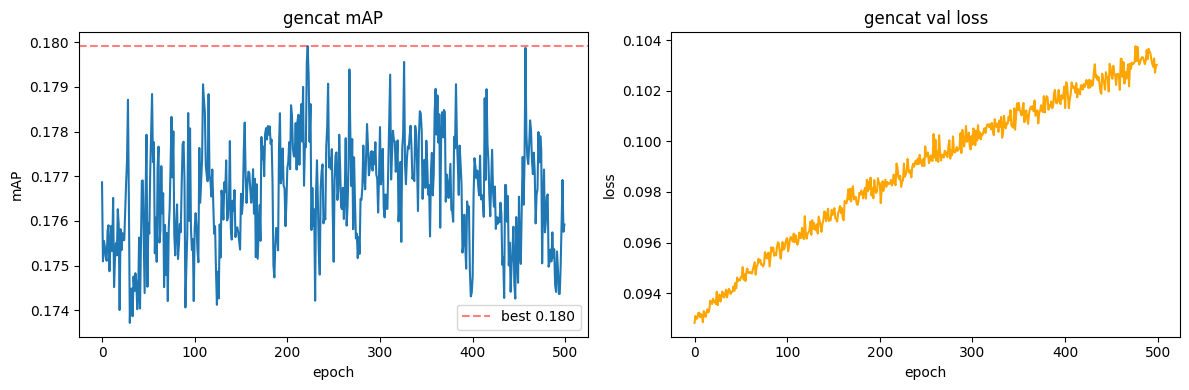

c:\Users\Moha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_ranking.py:1192: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
c:\Users\Moha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_ranking.py:1192: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
c:\Users\Moha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_ranking.py:1192: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
c:\Users\Moha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_ranking.py:1192: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
c:\Users\Moha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_ranking.py:1192: UserWarning: No positive class found in y_true

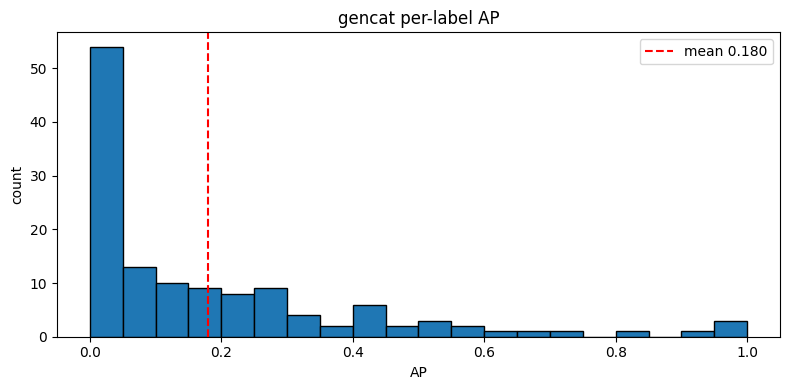

C:\Users\Moha\AppData\Local\Temp\ipykernel_19236\4267963738.py:58: UserWarning: Glyph 21332 (\N{CJK UNIFIED IDEOGRAPH-5354}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Moha\AppData\Local\Temp\ipykernel_19236\4267963738.py:58: UserWarning: Glyph 21147 (\N{CJK UNIFIED IDEOGRAPH-529B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Moha\AppData\Local\Temp\ipykernel_19236\4267963738.py:58: UserWarning: Glyph 12503 (\N{KATAKANA LETTER PU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Moha\AppData\Local\Temp\ipykernel_19236\4267963738.py:58: UserWarning: Glyph 12524 (\N{KATAKANA LETTER RE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Moha\AppData\Local\Temp\ipykernel_19236\4267963738.py:58: UserWarning: Glyph 12452 (\N{KATAKANA LETTER I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Moha\AppData\Local\Temp\ipykernel_19236\4267963738.py:58: UserWarning: Glyph 12510 (\N{KATAKANA LETTER MA}) missing 

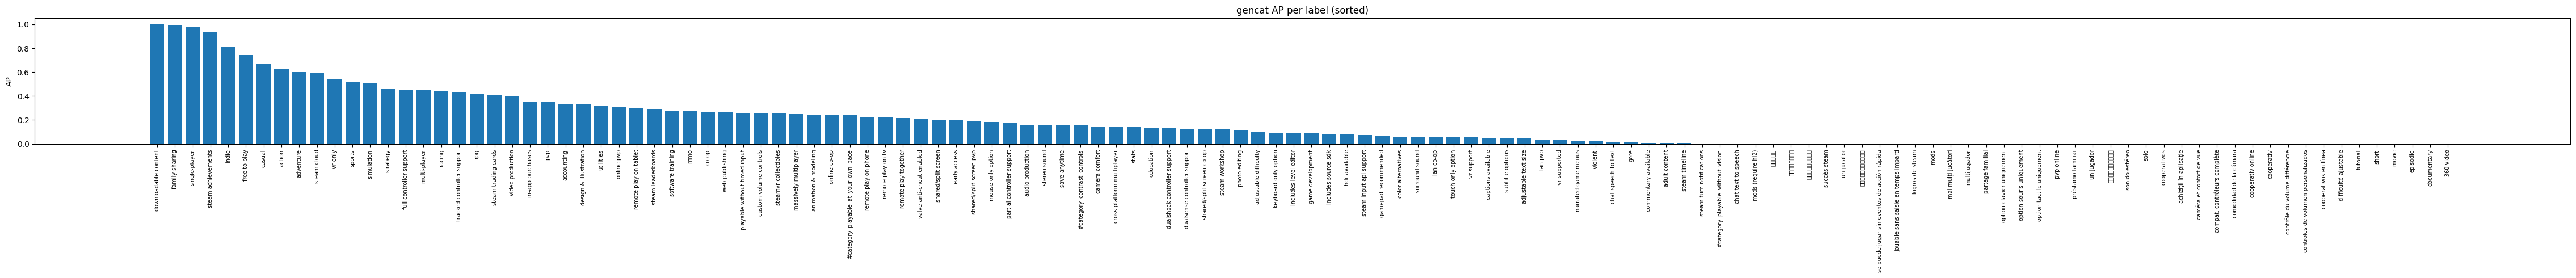

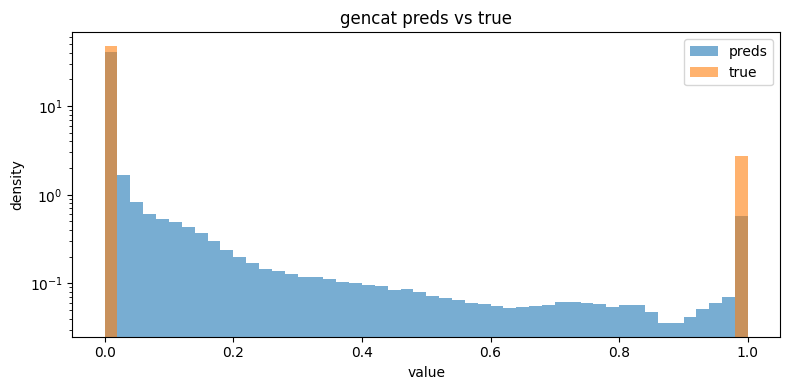

[gencat] test mAP    : 0.1798
[gencat] median AP   : 0.0898
[gencat] best val    : 0.1799 (epoch 222)
[gencat] labels >0.5 : 13/130



In [ ]:


#evalutating the models 
genres_names = [df_y.columns[i] for i in genres_idx]
ap_genres = eval_model(model_genres, mAP_genres, val_losses_genres, path_genres,
                       X_test, Y_test[:, genres_idx], genres_names, 'genres')

gencat_names = [df_y.columns[i] for i in gencat_idx]
ap_gencat = eval_model(model_gencat, mAP_gencat, val_losses_gencat, path_gencat,
                       X_test, Y_test[:, gencat_idx], gencat_names, 'gencat')

In [9]:
df_x.columns

Index(['emb_0', 'emb_1', 'emb_2', 'emb_3', 'emb_4', 'emb_5', 'emb_6', 'emb_7',
       'emb_8', 'emb_9',
       ...
       'average_playtime_forever', 'median_playtime_forever',
       'average_playtime_2weeks', 'median_playtime_2weeks', 'achievements',
       'dlc_count', 'windows', 'mac', 'linux', 'owners_mid'],
      dtype='str', length=401)

In [ ]:
#we should save target names for app.py
labels_path = ('labels/')

pd.DataFrame([genres_cols]).to_csv(labels_path + "labels_genres.csv", index=False)
pd.DataFrame([gencat_names]).to_csv(labels_path + "labels_gencat.csv", index=False)





NameError: name 'gencat_names' is not defined

In [18]:
tabular_cols = [c for c in df_x_t.columns if not c.startswith("emb_")]
pd.Series(tabular_cols).to_csv("labels/feature_columns.csv", index=False, header=False)

In [19]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer('all-MiniLM-L6-v2')
model.save("models/all-MiniLM-L6-v2")   # saves everything into that folder

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [20]:
import joblib, numpy as np
s = joblib.load("models/scaler.pkl")
np.savez("models/scaler.npz", mean=s.mean_, scale=s.scale_)